# Figure 4: Chattering in the Highly Overdamped Regime

**Model** — the integral feedback system of figures 2 and 3, with the
treatment $u$ acting on $\beta_1$ as in the optimal control notebook
(`02-optimal-control-proper-time.ipynb`):

$$\frac{dA}{dt} = \alpha\,(\mu - B), \qquad \frac{dB}{dt} = u\,\beta_1 A - \beta_2 B$$

$u = 1$ is off-treatment. The damping is set by the single dimensionless group
$q = \alpha\beta_1/\beta_2^2$ (the $q$ of the optimal control notebook), with
damping ratio $\zeta = 1/(2\sqrt{q})$: small $q$ is strongly overdamped. Here
$\alpha = \beta_1 = 1$, $\beta_2 = 10$, so $q = 0.01$ and $\zeta = 5$.

Notebook layout: panel A (highly overdamped relaxation to $\mu$),
then the optimal chattering strategy for a one-sided kill, then panel B
(timescale separation: $B$ follows the slow $A$), then panel C (mean kill
$\phi(A)$ while $A$ is held, for the one-sided and the quadratic kill), then
panel D (the duty cycle sets the level $A$ is held at), then panel E
(chattering vs constant treatment, for the one-sided and the quadratic kill).
An SI section at the end repeats panel E for the IFFL architecture.

In [147]:
"""Figure 4 — shared imports and plotting style."""
import sys
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()

In [148]:
# ======================================================================
# Palette (matches figures 1-3: one colour per model variable)
# ======================================================================
FEEDBACK = "black"       # A
REGULATED = "#e5a024"    # B
TUMOR = "#7A2E6E"        # C
INPUT = "#2166AC"        # u (as in figure 5)
REF = "#9A9A9A"          # reference lines

# ======================================================================
# Parameters
# ======================================================================
mu = 1.0                 # setpoint
alpha = 1.0
beta1 = 1.0
beta2 = 10.0             # strong damping
u_off = 1.0              # no treatment

q = alpha * beta1 / beta2**2          # = 0.01, as in the optimal control notebook
zeta = 1 / (2 * np.sqrt(q))           # = 5

# ======================================================================
# Model
# ======================================================================

def ab_rhs(t, y, u):
    """AB integral feedback with treatment u acting on beta1."""
    A, B = y
    return [alpha * (mu - B), u * beta1 * A - beta2 * B]

def eigenvalues(u=1.0):
    """Eigenvalues of the AB system: lambda^2 + beta2*lambda + u*alpha*beta1 = 0."""
    return np.roots([1, beta2, u * alpha * beta1])

**Panel A** — Highly overdamped regime ($q = 0.01$, $\zeta = 5$): $B$ started
away from steady state creeps back to $\mu$ without overshoot, on the slow
timescale $\approx \beta_2/(\alpha\beta_1) = 10$. Counterpart of panel A in
figures 2 and 3: same start, same time axis.

q = 0.01, damping ratio zeta = 5.0  (> 1: overdamped)
Eigenvalues: [-9.89897949 -0.10102051]  ->  slow timescale 1/|lambda_slow| = 9.9


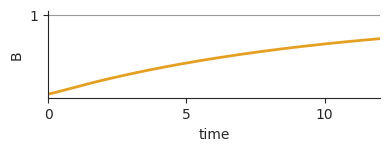

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_A.pdf


In [149]:
# Panel A: highly overdamped regime — B(t) relaxing to mu from off steady state.
# No treatment (u = 1). B starts displaced below mu, with A chosen so that
# dB/dt(0) = 0 (same start as figures 2 and 3, panel A). The fast eigenvalue
# (~ -beta2) is then barely excited, and B relaxes on the slow one
# (~ -alpha*beta1/beta2). Same window as figures 2 and 3, panel A, so the
# three read side by side: B is still visibly short of mu at the end.
T_A     = 12.0
delta_A = 0.5                      # initial displacement of B below mu
B0_A    = mu - delta_A
x0_A    = [beta2 * B0_A / (u_off * beta1), B0_A]

t_A = np.linspace(0, T_A, 2000)
sol = solve_ivp(ab_rhs, [0, T_A], x0_A, args=(u_off,), t_eval=t_A,
                rtol=1e-8, atol=1e-10)
B_A = sol.y[1]

lam = eigenvalues(u_off)
print(f'q = {q:g}, damping ratio zeta = {zeta:.1f}  (> 1: overdamped)')
print(f'Eigenvalues: {lam}  ->  slow timescale 1/|lambda_slow| = {1 / abs(lam).min():.1f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4, 1.6))

ax.axhline(mu, color=REF, lw=0.8, zorder=1)
ax.plot(t_A, B_A, color=REGULATED, lw=2)
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_yticks([1])
ax.set_xticks(np.arange(0, T_A + 1, 5))
ax.set_xlim(0, T_A)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure4_chattering_A.pdf')

**Optimal strategy for a one-sided kill** — from the last section of
`02-optimal-control-proper-time.ipynb`, rewritten in this notebook's notation.
There the on-treatment fraction is called $\alpha$; here it is the duty cycle $\delta$, since
$\alpha$ is already the integration rate of $A$.

The tumour follows $\dot C = C\,g(B)$ with the one-sided kill of figure 3,
$g(B) = c_1 - c_2\,(\mu - B)^+$. With $q \ll 1$, $B$ is fast and sits at its
quasi-steady state $B \approx u\,\beta_1 A/\beta_2 = u\,a\,\mu$, where
$a = A/A_\text{off}$ and $A_\text{off} = \beta_2\mu/\beta_1$ is the
off-treatment steady state of $A$. Switching between $u_\text{on}$ and
$u_\text{off}$ with on-fraction $\delta$ holds $A$ fixed when
$\delta(1 - u_\text{on}a) + (1-\delta)(1 - u_\text{off}a) = 0$:

$$\delta(a) = \frac{u_\text{off} - 1/a}{u_\text{off} - u_\text{on}}$$

For $a \in (1/u_\text{off},\, 1/u_\text{on})$, only the on-phases put $B$ below
$\mu$, so the average kill is $\delta(a)\,\mu\,(1 - u_\text{on}a)$. It is
largest at

$$a^* = \frac{1}{\sqrt{u_\text{on}u_\text{off}}} = \sqrt{2}, \qquad
\delta^* = \frac{\sqrt{u_\text{off}}}{\sqrt{u_\text{off}} + \sqrt{u_\text{on}}} = 2 - \sqrt{2} \approx 0.59,
\qquad \langle(\mu - B)^+\rangle = \mu\,\frac{\sqrt{u_\text{off}} - \sqrt{u_\text{on}}}{\sqrt{u_\text{off}} + \sqrt{u_\text{on}}} \approx 0.17\,\mu$$

(numbers for $u_\text{on} = 1/2$, $u_\text{off} = 1$). Under constant treatment
the kill instead fades to zero as $B$ adapts back to $\mu$.

**The switching period matters.** The derivation assumes $B$ is always at its
quasi-steady state, but after each switch $B$ takes $\sim 1/\beta_2$ to get
there. Switch faster than that and $B$ just averages to $\mu$, killing nothing.
The period $P$ must sit between the two timescales,
$1/\beta_2 \ll P \ll \beta_2/(\alpha\beta_1)$.

In [150]:
# ======================================================================
# Treatment, tumour, and the quasi-steady-state optimum
# ======================================================================
u_on = 0.5               # maximal dose: halves beta1
c1 = 0.05                # tumour growth rate (as in figure 3)
c2 = 1.0                 # tumour removal rate (as in figure 3)

A_off = beta2 * mu / beta1            # off-treatment steady state of A

def g_one_sided(B):
    """Net tumour growth rate, C' = C * g(B): kills only while B < mu."""
    return c1 - c2 * np.maximum(mu - B, 0.0)

def duty_hold(a):
    """On-fraction that holds A at a * A_off, with B at its quasi-steady state."""
    return (u_off - 1 / a) / (u_off - u_on)

def level_held(phi):
    """Level a = A / A_off held by on-fraction phi: the inverse of duty_hold."""
    return 1 / (phi * u_on + (1 - phi) * u_off)

def mean_kill(a):
    """Average one-sided kill (mu - B)^+ while A is held at a * A_off.
    Only the on-phases push B below mu."""
    return duty_hold(a) * mu * (1 - u_on * a)

a_opt = 1 / np.sqrt(u_on * u_off)     # = sqrt(2)
phi_opt = duty_hold(a_opt)            # = 2 - sqrt(2)
print(f'a* = {a_opt:.4f}  (A* = {a_opt * A_off:.2f}),  phi* = {phi_opt:.4f},  '
      f'mean kill = {mean_kill(a_opt):.4f},  mean g = {c1 - c2 * mean_kill(a_opt):.4f}')

# ======================================================================
# Simulation through a schedule of constant-u phases
# ======================================================================

def abc_rhs(t, y, u):
    """AB system plus log C, which grows at rate g(B)."""
    A, B, _ = y
    return [alpha * (mu - B), u * beta1 * A - beta2 * B, g_one_sided(B)]

def run_schedule(phases, y0, n_per_unit=200, rhs=abc_rhs):
    """Integrate (A, B, log C) through a list of (u, duration) phases.
    Returns t, y (rows A, B, log C) and u(t)."""
    t_out, y_out, u_out = [], [], []
    y, t0 = np.asarray(y0, float), 0.0
    for u, dur in phases:
        if dur <= 0:
            continue
        ts = np.linspace(t0, t0 + dur, max(int(dur * n_per_unit), 10))
        s = solve_ivp(rhs, [t0, t0 + dur], y, args=(u,), t_eval=ts,
                      rtol=1e-8, atol=1e-10)
        t_out.append(s.t); y_out.append(s.y); u_out.append(np.full(s.t.size, u))
        y, t0 = s.y[:, -1], t0 + dur
    return np.concatenate(t_out), np.concatenate(y_out, axis=1), np.concatenate(u_out)

def time_to_reach(a_target, y0):
    """Time for continuous treatment to bring A from y0 up to a_target * A_off."""
    hit = lambda t, y, u: y[0] - a_target * A_off
    hit.terminal, hit.direction = True, 1
    s = solve_ivp(abc_rhs, [0, 10 * beta2 / (alpha * beta1)], y0, args=(u_on,),
                  events=hit, rtol=1e-8, atol=1e-10)
    return s.t_events[0][0]

def pwm_phases(phi, P, duration):
    """On/off switching with period P and on-fraction phi, cut at `duration`."""
    phases, t = [], 0.0
    while t < duration:
        for u, dur in ((u_on, phi * P), (u_off, (1 - phi) * P)):
            dur = min(dur, duration - t)
            phases.append((u, dur)); t += dur
    return phases

def chattering_schedule(T, P, a_target=a_opt):
    """Treat continuously until A reaches a_target * A_off, then switch with
    period P and the on-fraction that holds A there. Ends on the horizon T."""
    t_hold = time_to_reach(a_target, y0_ss)
    phases = [(u_on, t_hold)] + pwm_phases(duty_hold(a_target), P, T - t_hold)
    return phases, t_hold

y0_ss = [A_off, mu, 0.0]              # off-treatment steady state, log C(0) = 0

a* = 1.4142  (A* = 14.14),  phi* = 0.5858,  mean kill = 0.1716,  mean g = -0.1216


**Panel B** — Timescale separation: $A$ moves slowly and $B$ adjusts almost
instantly, following $A$. Same layout as figure 1C: treatment (grey) is switched
on and later off again. At each switch $B$ jumps, within $\sim 1/\beta_2 = 0.1$,
onto its quasi-steady state $B_\text{qss} = u\,\beta_1 A/\beta_2$ (dashed), and
from then on just tracks $A$ as $A$ drifts on its slow timescale
$\sim \beta_2/(u\,\alpha\beta_1)$, 10–20 here. This is what the chattering
derivation assumes.

max |B - B_qss| beyond 5/beta2 after each switch: 0.0072


/tmp/ipykernel_1026320/253299204.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


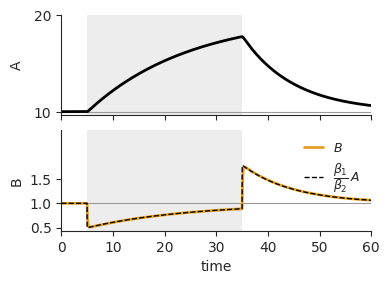

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_B.pdf


In [151]:
# Panel B: A is slow, B is fast and slaved to A.
# Off -> on -> off, starting from the untreated steady state. The dashed line
# on B is its quasi-steady state u*beta1*A/beta2, computed from A: B sits on
# it except for a ~1/beta2 transient right after each switch.
t_on_B, t_off_B = 5.0, 35.0
T_B = 60.0

phases_B = [(u_off, t_on_B), (u_on, t_off_B - t_on_B), (u_off, T_B - t_off_B)]
t_b, y_b, u_b = run_schedule(phases_B, y0_ss)
A_b, B_b = y_b[0], y_b[1]
B_qss = u_b * beta1 * A_b / beta2

settled = np.ones_like(t_b, bool)
for t_sw in (t_on_B, t_off_B):
    settled &= ~((t_b >= t_sw) & (t_b < t_sw + 5 / beta2))    # skip 5 fast time constants
print(f'max |B - B_qss| beyond 5/beta2 after each switch: {np.abs(B_b - B_qss)[settled].max():.4f}')

# ── Plot ──────────────────────────────────────────────────────────────
fig, (axA, axB) = plt.subplots(2, 1, figsize=(4, 2.8), sharex=True,
                               gridspec_kw=dict(hspace=0.15))

axA.axhline(A_off, color=REF, lw=0.8, zorder=1)
axA.plot(t_b, A_b, color=FEEDBACK, lw=2, zorder=2)
axA.set_ylabel('A')
axA.set_yticks([A_off, A_off / u_on])


axB.axhline(mu, color=REF, lw=0.8, zorder=1)
axB.plot(t_b, B_b, color=REGULATED, lw=2, zorder=2, label='$B$')
axB.plot(t_b, B_qss, color=FEEDBACK, lw=1, ls='--', zorder=3,
         label=r'$\dfrac{\beta_1}{\beta_2}\,A$')
axB.set_ylabel('B')
axB.set_yticks([0.5, 1, 1.5])
axB.set_xlabel('time')
axB.set_xticks(np.arange(0, T_B + 1, 10))
axB.set_ylim(top=2.5)
axB.legend(frameon=False, loc='upper right', fontsize=9, handlelength=1.5)

for ax in (axA, axB):
    ax.axvspan(t_on_B, t_off_B, color='0.93', lw=0, zorder=0)    # treatment window
    ax.set_xlim(0, T_B)
    sns.despine(ax=ax)
fig.align_ylabels([axA, axB])

plt.tight_layout()
plt.show()

save_fig(fig, 'figure4_chattering_B.pdf')

**Panel C** — The mean kill while switching holds $A$ at a fixed level, as a
function of that level ($A$ in units of $A_\text{off}$). Holding $A$ takes duty
cycle $\delta(A) = 2(A-1)/A$; $B$ then sits at $A/2$ during treatment and at $A$
off it, so with kill function $h$ the mean kill is

$$\phi(A) = 2\,\frac{A-1}{A}\, h\!\left(1 - \tfrac{1}{2}A\right) + \frac{2-A}{A}\, h\!\left(1 - A\right)$$

($u_\text{on} = 1/2$, $u_\text{off} = 1$, $\mu = 1$). For the one-sided kill
$h(z) = \max(z, 0)$ only the on-phases contribute, and $\phi$ peaks at
$A^* = \sqrt 2$ with $\phi = 0.17$. For the quadratic kill $h(z) = z^2$ the
off-phases contribute too, and the peak moves to the midpoint $A^* = 1.5$ with
$\phi = 0.125$. Both vanish at the two steady states $A = 1$ and $A = 2$, where
$B$ sits at $\mu$.

$h(z) = \max(z, 0)$: max phi = 0.1716 at A = 1.414 (theory 1.414)
$h(z) = z^2$: max phi = 0.1250 at A = 1.501 (theory 1.500)


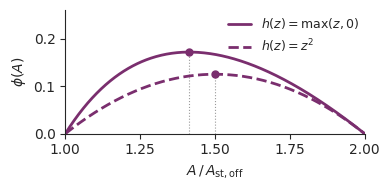

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_C.pdf


In [178]:
# Panel C: mean kill phi(A) while switching holds A, for the two kills.
# A is in units of A_off. Holding A needs duty cycle delta = duty_hold(A); B sits
# at u_on*A*mu in the on-phases and at u_off*A*mu in the off-phases, so the mean
# kill is the delta-weighted average of h(mu - B) over the two. For u_on = 1/2,
# u_off = 1 (and mu = 1) this is
#   phi(A) = 2 (A-1)/A h(1 - A/2) + (2-A)/A h(1 - A).

def phi_kill(A, h):
    """Mean kill h(mu - B) while switching holds A (in units of A_off)."""
    delta = duty_hold(A)
    return delta * h(mu - u_on * A * mu) + (1 - delta) * h(mu - u_off * A * mu)

kills_C = [   # (h, label, line style, argmax from the theory above, its label)
    (lambda z: np.maximum(z, 0), r'$h(z) = \max(z, 0)$', '-', a_opt, r'$\sqrt{2}$'),
    (lambda z: z**2, r'$h(z) = z^2$', '--', (1 / u_on + 1 / u_off) / 2, '1.5'),
]
A_C = np.linspace(1 / u_off, 1 / u_on, 400)

fig, ax = plt.subplots(figsize=(4, 2))

for h, label, ls, A_star, A_star_label in kills_C:
    phi_C = phi_kill(A_C, h)
    print(f'{label}: max phi = {phi_C.max():.4f} at A = {A_C[phi_C.argmax()]:.3f} '
          f'(theory {A_star:.3f})')
    ax.plot(A_C, phi_C, color=TUMOR, lw=2, ls=ls, label=label)
    ax.plot(A_star, phi_kill(A_star, h), 'o', color=TUMOR, ms=5, zorder=3)
    ax.vlines(A_star, 0, phi_kill(A_star, h), color=REF, lw=0.8, ls=':', zorder=1)
    # ax.annotate(A_star_label, (A_star, phi_kill(A_star, h)), xytext=(0, 6),
    #             textcoords='offset points', ha='center', va='bottom',
    #             color=TUMOR, fontsize=9)

ax.set_xlim(1 / u_off, 1 / u_on)
ax.set_ylim(0, 0.26)
ax.set_yticks([0, 0.1, 0.2])
ax.set_xticks([1, 1.25, 1.5, 1.75, 2])
ax.set_xlabel(r'$A\,/\,A_\mathrm{st,off}$')
ax.set_ylabel(r'$\phi(A)$')
ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(1.02, 1.04),
          fontsize=9, handlelength=1.8)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig, 'figure4_chattering_C.pdf')

**Panel D** — The duty cycle sets the level $A$ is held at. Under constant
control $A$ settles at $A_\text{off} = \beta_2\mu/\beta_1$ (no treatment) or
$A_\text{on} = A_\text{off}/u_\text{on}$ (continuous treatment). Switching with
duty cycle $\delta$ (on-fraction) averages the two vector fields, and $A$
settles at $a(\delta)\,A_\text{off}$ with
$a(\delta) = 1/(\delta\,u_\text{on} + (1-\delta)\,u_\text{off})$, which sweeps
$[A_\text{off}, A_\text{on}]$ as $\delta$ goes from 0 to 1. Two runs from the
untreated steady state, a small and a large duty cycle: top row the input $u$,
bottom row $A$, with the predicted level $a(\delta)A_\text{off}$ dotted. The
level depends only on $\delta$, not on the period $P$, which only sets the
ripple; $P = 4$ is used so the individual pulses are visible.

delta = 0.2: predicted A = 11.11, mean A over the last 28 = 11.11
delta = 0.8: predicted A = 16.67, mean A over the last 28 = 16.62


/tmp/ipykernel_1026320/889483084.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


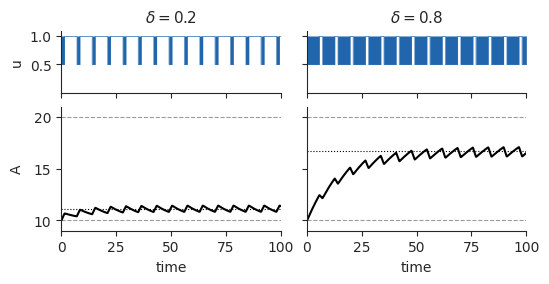

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_D.pdf


In [179]:
# Panel D: the duty cycle delta sets the level A is held at.
# Two runs from the untreated steady state, a small and a large duty cycle;
# A settles at level_held(delta) * A_off. A only sees the average of u, so the
# level is independent of P (within 0.1% at P = 0.5 and P = 2); P only sets the
# ripple, ~0.3 (delta = 0.2) and ~0.7 (delta = 0.8) at P = 4. The horizon is
# long because A's slow rate shrinks with the mean dose: at delta = 0.8 the time
# constant is ~17, and A is still ~2% short of its level at t = 60.
T_D = 100.0
P_D = 7.0
deltas_D = (0.2, 0.8)

fig, axs = plt.subplots(2, 2, figsize=(6, 2.6), sharex=True, sharey='row',
                        gridspec_kw=dict(height_ratios=[1, 2], hspace=0.15, wspace=0.12))

for j, delta in enumerate(deltas_D):
    t_d, y_d, u_d = run_schedule(pwm_phases(delta, P_D, T_D), y0_ss)
    A_held = level_held(delta) * A_off
    print(f'delta = {delta}: predicted A = {A_held:.2f}, '
          f'mean A over the last {4 * P_D:g} = {y_d[0, t_d >= T_D - 4 * P_D].mean():.2f}')

    ax = axs[0, j]
    ax.fill_between(t_d, u_d, u_off, color=INPUT, lw=0.2, joinstyle='miter')    # treatment blocks; the edge matches the line width
    ax.plot(t_d, u_d, color=INPUT, lw=0.2, solid_joinstyle='miter')    # u(t), joins the blocks
    ax.set_title(rf'$\delta = {delta:g}$', fontsize=11)

    ax = axs[1, j]
    for level in (A_off, A_off / u_on):    # the two steady states of A
        ax.axhline(level, color=REF, lw=0.8, ls='--', zorder=1)
    ax.axhline(A_held, color=FEEDBACK, lw=0.8, ls=':', zorder=1)
    ax.plot(t_d, y_d[0], color=FEEDBACK, lw=1.5, zorder=2)
    ax.set_xlabel('time')

axs[0, 0].set_ylabel('u')
axs[0, 0].set_yticks([u_on, u_off])
axs[0, 0].set_ylim(0, 1.1 * u_off)
axs[1, 0].set_ylabel('A')
axs[1, 0].set_ylim(A_off - 1, A_off / u_on + 1)
axs[1, 0].set_yticks([A_off, 1.5 * A_off, A_off / u_on])
for ax in axs.flat:
    ax.set_xlim(0, T_D)
    ax.set_xticks(np.arange(0, T_D + 1, 25))
    sns.despine(ax=ax)
fig.align_ylabels(axs[:, 0])

plt.tight_layout()
plt.show()

save_fig(fig, 'figure4_chattering_D.pdf')

**Panel E** — Chattering beats constant treatment ($q = 0.01$, one-sided kill).
Both start from the off-treatment steady state. Constant treatment kills at
first, but $B$ adapts back to $\mu$ and the tumour regrows. The optimal strategy
treats until $A$ reaches $a^*A_\text{off}$, then switches on and off with
on-fraction $\delta^*$, holding $B$ below $\mu$ for the whole of every on-phase.
Top row: the treatment $u(t)$ of each strategy. This panel uses a faster tumour
growth rate, $c_1 = 0.1$ (vs $0.05$ elsewhere), with $c_2 = 1$; only the ratio
$c_1/c_2$ shapes the $\log C$ curves, and at $0.1$ the regrowth under constant
treatment is clearly visible.

continuous treatment until t = 10.74, then chattering with P = 2
mean kill while chattering: 0.1500 (quasi-steady-state value 0.1716)
log C(T): optimal -6.51,  constant -1.82


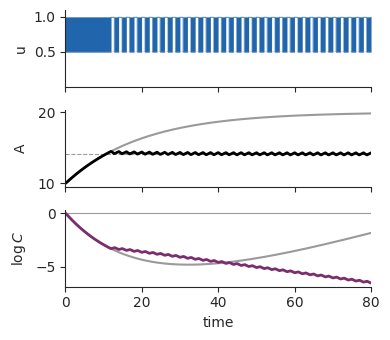

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_E_one_sided.pdf


<Figure size 160x70 with 0 Axes>

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_E_legend.pdf


In [183]:
# Panel E: optimal chattering vs constant treatment, one-sided kill.
# P sits between B's timescale (1/beta2 = 0.1) and A's (beta2/(alpha*beta1) = 10):
# at P = 2 the average kill is ~87% of the quasi-steady-state value, and A
# drifts by < 1% from a* over the run. The horizon must be long: constant
# treatment's kill fades only on A's slow timescale (~0.5*exp(-0.05 t)), so it
# keeps up with chattering until t ~ 45, then the tumour regrows.
# The growth rate is doubled here (c1_E = 0.1, vs c1 = 0.05 elsewhere). log C is
# c1*t minus c2 times the accumulated kill, so only c1/c2 shapes the plot; at 0.1
# constant treatment turns around and regrows while chattering keeps killing.
# The quadratic panel keeps c1 = 0.05: its chattering kill (~0.1) would barely
# beat c1 = 0.1.
T_E = 80.0
P_E = 2.0
c1_E = 0.1

def abc_rhs_E(t, y, u):
    """abc_rhs with panel E's growth rate c1_E in place of c1."""
    A, B, _ = y
    return [alpha * (mu - B), u * beta1 * A - beta2 * B,
            c1_E - c2 * np.maximum(mu - B, 0.0)]

phases_opt, t_hold = chattering_schedule(T_E, P_E)
t_opt, y_opt, u_opt = run_schedule(phases_opt, y0_ss, rhs=abc_rhs_E)
t_const, y_const, u_const = run_schedule([(u_on, T_E)], y0_ss, rhs=abc_rhs_E)

hold = t_opt >= t_hold
print(f'continuous treatment until t = {t_hold:.2f}, then chattering with P = {P_E:g}')
print(f'mean kill while chattering: {np.mean(np.maximum(mu - y_opt[1, hold], 0)):.4f} '
      f'(quasi-steady-state value {mean_kill(a_opt):.4f})')
print(f'log C(T): optimal {y_opt[2, -1]:.2f},  constant {y_const[2, -1]:.2f}')

# ── Plot ──────────────────────────────────────────────────────────────

def plot_vs_constant(opt, const, A_target, T):
    """Stacked u, A, log C of the optimal schedule against constant treatment.
    `opt` and `const` are (t, y, u) from run_schedule."""
    (t_o, y_o, u_o), (t_c, y_c, u_c) = opt, const
    fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(4, 3.5), sharex=True)

    ax = axs[0]
    LW = 0.2
    ax.plot(t_c, u_c, color=REF, lw=LW)    # same width as the blocks' edge, so it does not stick out below them
    ax.fill_between(t_o, u_o, u_off, color=INPUT, lw=LW, joinstyle='miter')    # treatment blocks; the edge matches the line width
    ax.plot(t_o, u_o, color=INPUT, lw=LW, solid_joinstyle='miter')    # u(t), joins the blocks
    ax.set_ylabel('u')
    ax.set_yticks([u_on, u_off])
    ax.set_ylim(0, 1.1 * u_off)

    ax = axs[1]
    ax.plot(t_c, y_c[0], color=REF, lw=1.5)
    ax.plot(t_o, y_o[0], color=FEEDBACK, lw=2)
    ax.axhline(A_target, color=REF, lw=0.8, ls='--', zorder=1)
    ax.set_ylabel('A')

    ax = axs[2]
    ax.plot(t_c, y_c[2], color=REF, lw=1.5, label='constant')
    ax.plot(t_o, y_o[2], color=TUMOR, lw=2, label='optimal')
    ax.axhline(0, color=REF, lw=0.8, zorder=1)
    ax.set_ylabel(r'$\log C$')
    ax.set_xlabel('time')
    ax.set_xticks(np.arange(0, T + 1, 20))

    for ax in axs:
        ax.set_xlim(0, T)
        sns.despine(ax=ax)
    fig.align_ylabels(axs)

    plt.tight_layout()
    return fig, axs

fig, axs = plot_vs_constant((t_opt, y_opt, u_opt), (t_const, y_const, u_const),
                            a_opt * A_off, T_E)
plt.show()

save_fig(fig, 'figure4_chattering_E_one_sided.pdf')

# Legend as its own figure, so it can sit beside the panel.
handles, labels = axs[2].get_legend_handles_labels()
fig_leg = plt.figure(figsize=(1.6, 0.7))
fig_leg.legend(handles, labels, frameon=False, loc='center', fontsize=11)
plt.show()

save_fig(fig_leg, 'figure4_chattering_E_legend.pdf')

**Panel E, quadratic kill** — the same comparison for the two-sided kill
$g(B) = c_1 - c_2\,(\mu - B)^2$ (same $c_2$, dose, $P$ and horizon, but
$c_1 = 0.05$ as in figure 3: the quadratic kill while chattering is only
$\approx 0.1$, so the one-sided panel's $c_1 = 0.1$ would cancel it).
Now the off-phases kill too, since $B$ sits above $\mu$ there. With the hold
condition $\delta(1 - u_\text{on}a) = -(1-\delta)(1 - u_\text{off}a)$, the
average kill while $A$ is held at $a\,A_\text{off}$ is

$$\langle(\mu - B)^2\rangle = \delta(1 - u_\text{on}a)^2 + (1-\delta)(1 - u_\text{off}a)^2
= \mu^2\,(u_\text{off}a - 1)(1 - u_\text{on}a),$$

which peaks halfway between $A$'s two steady states:

$$a^* = \frac{1}{2}\left(\frac{1}{u_\text{on}} + \frac{1}{u_\text{off}}\right) = 1.5, \qquad
\delta^* = \frac{u_\text{off}}{u_\text{on} + u_\text{off}} = \frac{2}{3}, \qquad
\langle(\mu - B)^2\rangle = \mu^2\,\frac{(u_\text{off} - u_\text{on})^2}{4\,u_\text{on}u_\text{off}} = 0.125\,\mu^2.$$

So the held level moves up from $\sqrt 2$ (one-sided) to $1.5$, and the
on-fraction from $0.59$ to $2/3$. (The remark in notebook 02 that the numerics
held $A \approx \sqrt 2$ for both kills is accurate only for the one-sided one.)

a* = 1.5000  (A* = 15.00),  phi* = 0.6667,  mean kill = 0.1250,  mean g = -0.0750
continuous treatment until t = 13.89, then chattering with P = 2
mean kill while chattering: 0.0989 (quasi-steady-state value 0.1250)
log C(T): optimal -4.40,  constant 1.50


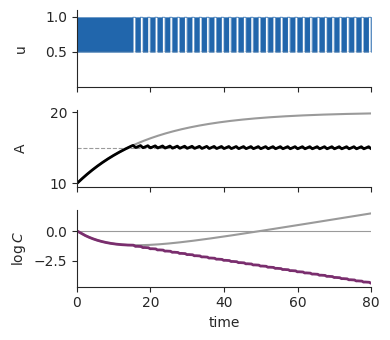

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_E_quadratic.pdf


In [184]:
# Panel E, quadratic kill: g(B) = c1 - c2*(mu - B)^2. Same c2, dose, period and
# horizon as the one-sided panel, but the shared c1 = 0.05 rather than c1_E = 0.1
# (see that cell); the kill and the held level change too. The off-phases kill too here (B > mu), so the optimum moves up
# from sqrt(2) to the midpoint 1.5 of A's two steady states. At P = 2 the
# average kill is ~79% of the quasi-steady-state value.

def g_quadratic(B):
    """Net tumour growth rate, C' = C * g(B): kills on either side of mu."""
    return c1 - c2 * (mu - B)**2

def mean_kill_quad(a):
    """Average quadratic kill (mu - B)^2 while A is held at a * A_off."""
    return mu**2 * (u_off * a - 1) * (1 - u_on * a)

def abc_rhs_quad(t, y, u):
    """AB system plus log C, which grows at rate g_quadratic(B)."""
    A, B, _ = y
    return [alpha * (mu - B), u * beta1 * A - beta2 * B, g_quadratic(B)]

a_opt_q = (1 / u_on + 1 / u_off) / 2           # = 1.5
phi_opt_q = duty_hold(a_opt_q)                 # = u_off / (u_on + u_off) = 2/3
print(f'a* = {a_opt_q:.4f}  (A* = {a_opt_q * A_off:.2f}),  phi* = {phi_opt_q:.4f},  '
      f'mean kill = {mean_kill_quad(a_opt_q):.4f},  mean g = {c1 - c2 * mean_kill_quad(a_opt_q):.4f}')

phases_q, t_hold_q = chattering_schedule(T_E, P_E, a_target=a_opt_q)
t_q, y_q, u_q = run_schedule(phases_q, y0_ss, rhs=abc_rhs_quad)
t_qc, y_qc, u_qc = run_schedule([(u_on, T_E)], y0_ss, rhs=abc_rhs_quad)

hold_q = t_q >= t_hold_q
print(f'continuous treatment until t = {t_hold_q:.2f}, then chattering with P = {P_E:g}')
print(f'mean kill while chattering: {np.mean((mu - y_q[1, hold_q])**2):.4f} '
      f'(quasi-steady-state value {mean_kill_quad(a_opt_q):.4f})')
print(f'log C(T): optimal {y_q[2, -1]:.2f},  constant {y_qc[2, -1]:.2f}')

fig, axs = plot_vs_constant((t_q, y_q, u_q), (t_qc, y_qc, u_qc), a_opt_q * A_off, T_E)
plt.show()

save_fig(fig, 'figure4_chattering_E_quadratic.pdf')

---
# SI: chattering in the IFFL architecture

**SI: IFFL** — Chattering also works for the IFFL (fold-change detector) of
`03-optimal-control-iffl.ipynb`, where the drug lowers the input $u$ that
activates both $A$ and $B$:

$$\dot A = \alpha_1\,(u\,A_\text{off} - A), \qquad \dot B = \alpha_2\left(B_\text{st}\,\frac{u\,A_\text{off}}{A} - B\right)$$

($\alpha_1, \alpha_2$ are the IFFL's turnover rates, notebook 03's notation, not
the NFL's $\alpha$.) The eigenvalues are exactly $-\alpha_1$ and $-\alpha_2$;
$\alpha_1 = 0.1$, $\alpha_2 = 10$ matches the NFL timescales above, and is
$r = \alpha_1/\alpha_2 = 0.01$, the chattering regime of notebook 03.

The quasi-steady-state argument carries over with $B \approx B_\text{st}\,u/a$
($a = A/A_\text{off}$): switching holds $A$ when the mean input equals $a$, so
$\delta(a) = (u_\text{off} - a)/(u_\text{off} - u_\text{on})$.

- **One-sided kill**: the average kill $\delta(a)\,B_\text{st}(1 - u_\text{on}/a)$
  peaks at $a^* = \sqrt{u_\text{on}u_\text{off}} \approx 0.71$, with the same
  $\delta^* = 2 - \sqrt 2$ and the same kill, $\approx 0.17\,B_\text{st}$, as the NFL.
- **Quadratic kill**: the mean deviation is zero, so the average kill is the
  variance of $B$, $B_\text{st}^2\,(u_\text{off} - a)(a - u_\text{on})/a^2$. It
  peaks at the harmonic mean $a^* = 2u_\text{on}u_\text{off}/(u_\text{on} + u_\text{off}) = 2/3$,
  the reciprocal of the NFL's $1.5$, with the same $\delta^* = 2/3$ and kill
  $0.125\,B_\text{st}^2$.

In both cases the optimum mirrors the NFL's. The difference is direction:
treatment pushes $A$ down here, so the strategy treats until $A$ falls to
$a^*A_\text{off}$, then switches. Same tumour, dose, period $P$ and horizon as
panel E, and the same layout: $u$, $A$ and $\log C$, against constant treatment (grey).

r = 0.01,  P = 2
one-sided: a* = 0.7071,  phi* = 0.5858,  treat until t = 8.81,  mean kill while chattering = 0.1495,  log C(T): chattering -10.06, constant -2.93


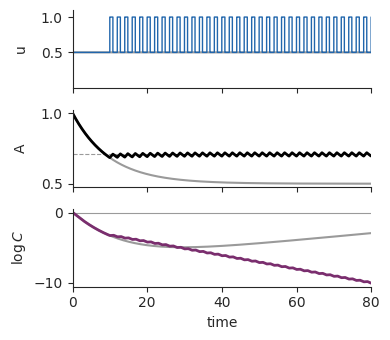

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_SI_iffl.pdf
quadratic: a* = 0.6667,  phi* = 0.6667,  treat until t = 10.99,  mean kill while chattering = 0.0969,  log C(T): chattering -4.21, constant 2.08


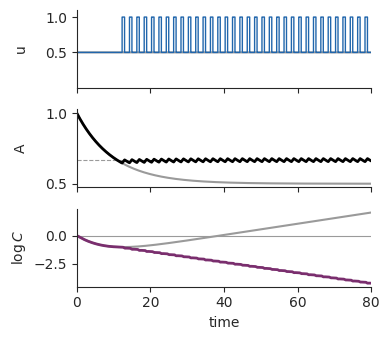

Figure saved to /home/amir/RL/autodiff-control/plots/figure4_chattering_SI_iffl_quadratic.pdf


In [155]:
# SI: chattering in the IFFL (fold-change detector), for both kills.
# A' = alpha1*(u*A_off - A), B' = alpha2*(B_st*u*A_off/A - B), with
# eigenvalues -alpha1, -alpha2 matching the NFL's (~ -0.1, ~ -9.9).
IFFL = dict(alpha1=0.1, alpha2=10.0, A_off=1.0, B_st=mu)

def iffl_rhs(t, y, u, p=IFFL, g=g_one_sided):
    """IFFL plus log C, which grows at rate g(B) (B_st = mu, so g is shared)."""
    A, B, _ = y
    return [p['alpha1'] * (u * p['A_off'] - A),
            p['alpha2'] * (p['B_st'] * u * p['A_off'] / A - B),
            g(B)]

def iffl_rhs_quad(t, y, u):
    return iffl_rhs(t, y, u, g=g_quadratic)

def iffl_duty_hold(a):
    """On-fraction that holds A at a * A_off: the mean input must equal a."""
    return (u_off - a) / (u_off - u_on)

y0_ff = [IFFL['A_off'], IFFL['B_st'], 0.0]

def iffl_chattering(a_target, rhs):
    """Treat continuously until A falls to a_target * A_off, then switch with
    period P_E. Returns the chattering and constant-treatment runs, and the
    time the switching starts."""
    hit = lambda t, y, u: y[0] - a_target * IFFL['A_off']
    hit.terminal, hit.direction = True, -1
    t_hold = solve_ivp(rhs, [0, 10 / IFFL['alpha1']], y0_ff, args=(u_on,),
                       events=hit, rtol=1e-8, atol=1e-10).t_events[0][0]
    phases = [(u_on, t_hold)] + pwm_phases(iffl_duty_hold(a_target), P_E, T_E - t_hold)
    return (run_schedule(phases, y0_ff, rhs=rhs),
            run_schedule([(u_on, T_E)], y0_ff, rhs=rhs), t_hold)

# The QSS optima mirror the NFL's: a* is the reciprocal, phi* is the same.
a_opt_ff = np.sqrt(u_on * u_off)                       # one-sided: 1 / sqrt(2)
a_opt_ff_q = 2 * u_on * u_off / (u_on + u_off)         # quadratic: 2/3 = 1 / 1.5

print(f'r = {IFFL["alpha1"] / IFFL["alpha2"]:g},  P = {P_E:g}')
for name, a_target, rhs, kill, fname in [
        ('one-sided', a_opt_ff, iffl_rhs, lambda B: np.maximum(mu - B, 0),
         'figure4_chattering_SI_iffl.pdf'),
        ('quadratic', a_opt_ff_q, iffl_rhs_quad, lambda B: (mu - B)**2,
         'figure4_chattering_SI_iffl_quadratic.pdf')]:
    opt, const, t_hold_ff = iffl_chattering(a_target, rhs)
    t_ff, y_ff, _ = opt
    print(f'{name}: a* = {a_target:.4f},  phi* = {iffl_duty_hold(a_target):.4f},  '
          f'treat until t = {t_hold_ff:.2f},  '
          f'mean kill while chattering = {np.mean(kill(y_ff[1, t_ff >= t_hold_ff])):.4f},  '
          f'log C(T): chattering {y_ff[2, -1]:.2f}, constant {const[1][2, -1]:.2f}')

    fig, axs = plot_vs_constant(opt, const, a_target * IFFL['A_off'], T_E)
    axs[1].set_yticks([0.5, 1])
    plt.show()

    save_fig(fig, fname)